# Part 2 - YOLO colony detection

In [28]:
from pathlib import Path
import shutil
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

RANDOM = 22112026

IMAGE_SIZE = 896
EPOCHS = 100
BATCH_SIZE = 8
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'

random.seed(RANDOM)
np.random.seed(RANDOM)
torch.manual_seed(RANDOM)

In [15]:
HOMETASK_ROOT = Path('hometask')

detection_table = pd.DataFrame([
    {
        'person': person,
        'image': image.name,
        'label_exists': (HOMETASK_ROOT / 'labeled' / f'{person}_part' / 'obj_train_data' / f'{image.stem}.txt').exists(),
    }
    for person in ['oleh', 'zhenya']
    for image in sorted((HOMETASK_ROOT / person).iterdir())
])
display(detection_table.head())
print('Images:', len(detection_table))
print('Missing labels:', int((~detection_table['label_exists']).sum()))

,person,image,label_exists
0,oleh,18 count.jpg,True
1,oleh,19 open.jpg,True
2,oleh,21 count.jpg,True
3,oleh,37 open.jpg,True
4,oleh,40 open.jpg,True


Images: 59
Missing labels: 0


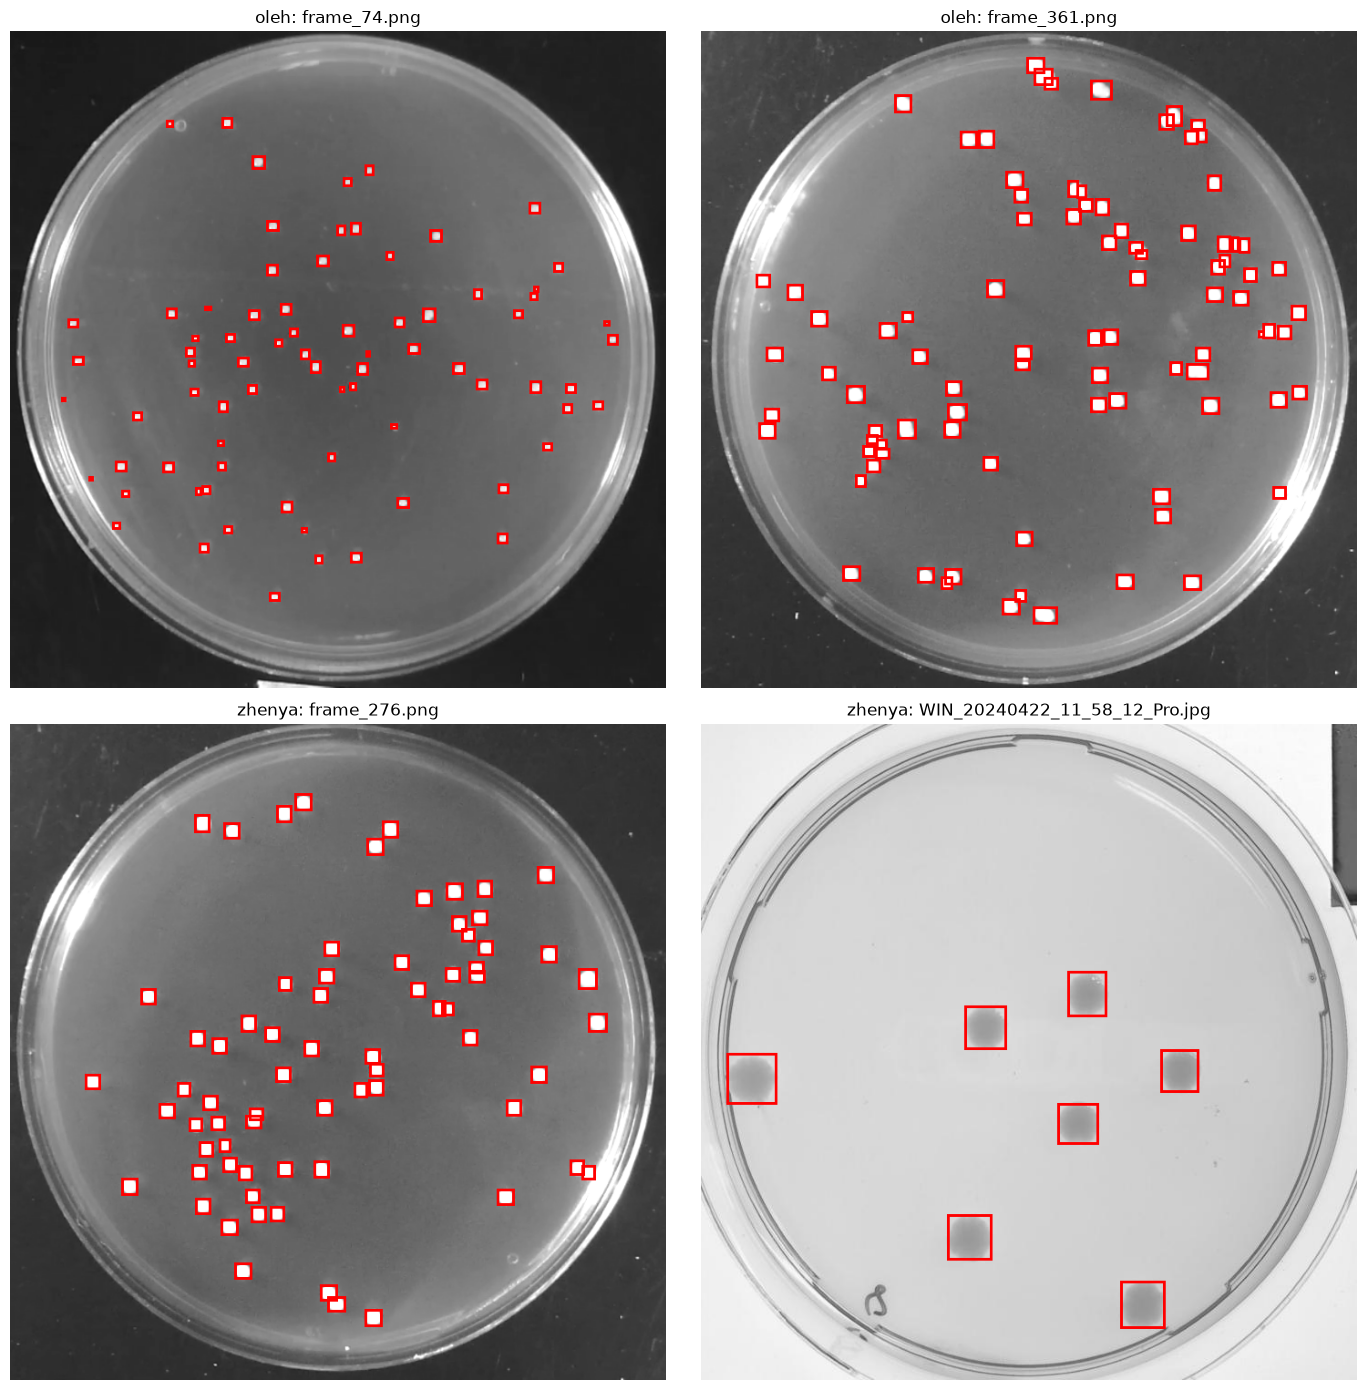

In [16]:
figure, axes = plt.subplots(2, 2, figsize=(14, 14))

for row, person in enumerate(['oleh', 'zhenya']):
    images = sorted((HOMETASK_ROOT / person).iterdir())
    for axis, image_path in zip(axes[row], random.sample(images, 2)):
        image = Image.open(image_path).convert('RGB')
        width, height = image.size
        draw = ImageDraw.Draw(image)

        label_path = HOMETASK_ROOT / 'labeled' / f'{person}_part' / 'obj_train_data' / f'{image_path.stem}.txt'
        for line in label_path.read_text().splitlines():
            _, x, y, w, h = map(float, line.split())
            draw.rectangle(
                [(x - w / 2) * width, (y - h / 2) * height, (x + w / 2) * width, (y + h / 2) * height],
                outline='red',
                width=3,
            )

        axis.imshow(image)
        axis.set_title(f'{person}: {image_path.name}')
        axis.axis('off')

plt.tight_layout()
plt.show()

## Zhenya

In [26]:
zhenya_table = detection_table[detection_table['person'] == 'zhenya']
train_table, val_table = train_test_split(zhenya_table, test_size=0.2, random_state=RANDOM)

print('Train:', len(train_table))
print('Val:', len(val_table))

Train: 24
Val: 6


In [27]:
ZHENYA_ROOT = Path('data/colonies_zhenya')

for split, table in [('train', train_table), ('val', val_table)]:
    (ZHENYA_ROOT / 'images' / split).mkdir(parents=True, exist_ok=True)
    (ZHENYA_ROOT / 'labels' / split).mkdir(parents=True, exist_ok=True)
    for _, row in table.iterrows():
        image_path = HOMETASK_ROOT / row['person'] / row['image']
        label_path = HOMETASK_ROOT / 'labeled' / f"{row['person']}_part" / 'obj_train_data' / f'{image_path.stem}.txt'
        shutil.copy(image_path, ZHENYA_ROOT / 'images' / split / image_path.name)
        shutil.copy(label_path, ZHENYA_ROOT / 'labels' / split / label_path.name)

ZHENYA_YAML = ZHENYA_ROOT / 'colonies.yaml'
ZHENYA_YAML.write_text(
    f'path: {ZHENYA_ROOT.resolve()}\n'
    'train: images/train\n'
    'val: images/val\n'
    'names:\n'
    '  0: colony\n'
)

130

In [29]:
zhenya_model = YOLO('yolo11n.pt')

zhenya_results = zhenya_model.train(
    data=ZHENYA_YAML,
    imgsz=IMAGE_SIZE,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    device=DEVICE,
    seed=RANDOM,
    project='runs',
    name='yolo11n_colonies_zhenya',
)

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.197 🚀 Python-3.11.15 torch-2.11.0 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/colonies_zhenya/colonies.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=896, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937,

2026/11/22 19:19:05 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.


MLflow: logging run_id(94dc2296c7eb41049f75d24f866a6a74) to sqlite:////Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/lab7/mlflow.db
MLflow: disable with 'yolo settings mlflow=False'
Using 24 train, 6 val images for fraction=1.0 at imgsz=896
Using 0 dataloader workers
Logging results to /Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/runs/detect/runs/yolo11n_colonies_zhenya
Starting training for 100 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      1/100      9.44G      1.922      4.131      1.058       1095        896: 100% ━━━━━━━━━━━━ 3/3 1.9s/it 5.6s2.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.6s/it 2.6s
                   all          6        948    0.00248    0.00844      0.003    0.00285

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/100      7.68G      2.355      2.764      1.089        980        896: 100% ━━━━━━━━━━━━ 3/3 1.0s/

In [30]:
zhenya_best_model = YOLO(Path(zhenya_model.trainer.save_dir) / 'weights' / 'best.pt')
zhenya_val_results = zhenya_best_model.val(data=ZHENYA_YAML, imgsz=IMAGE_SIZE, device=DEVICE, split='val')

display(pd.DataFrame({
    'precision': [zhenya_val_results.box.mp],
    'recall': [zhenya_val_results.box.mr],
    'mAP50': [zhenya_val_results.box.map50],
    'mAP50-95': [zhenya_val_results.box.map],
}))

Ultralytics 8.4.197 🚀 Python-3.11.15 torch-2.11.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 815.0±503.2 MB/s, size: 219.1 KB)
val: Scanning /Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/lab7/data/colonies_zhenya/labels/val.cache... 6 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6/6 6.3Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 428 objects (val=428), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=428 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.2it/s 0.2s
                   all          6        948      0.807      0.699      0.715      0.406
Speed: 0.2ms preprocess, 7.3ms inference, 0.0ms loss, 2.4ms postpro

,precision,recall,mAP50,mAP50-95
0,0.807386,0.699367,0.71453,0.405936



0: 896x896 84 colonys, 107.7ms
1: 896x896 365 colonys, 107.7ms
2: 896x896 15 colonys, 107.7ms
3: 896x896 8 colonys, 107.7ms
Speed: 8.0ms preprocess, 107.7ms inference, 8.2ms postprocess per image at shape (1, 3, 896, 896)


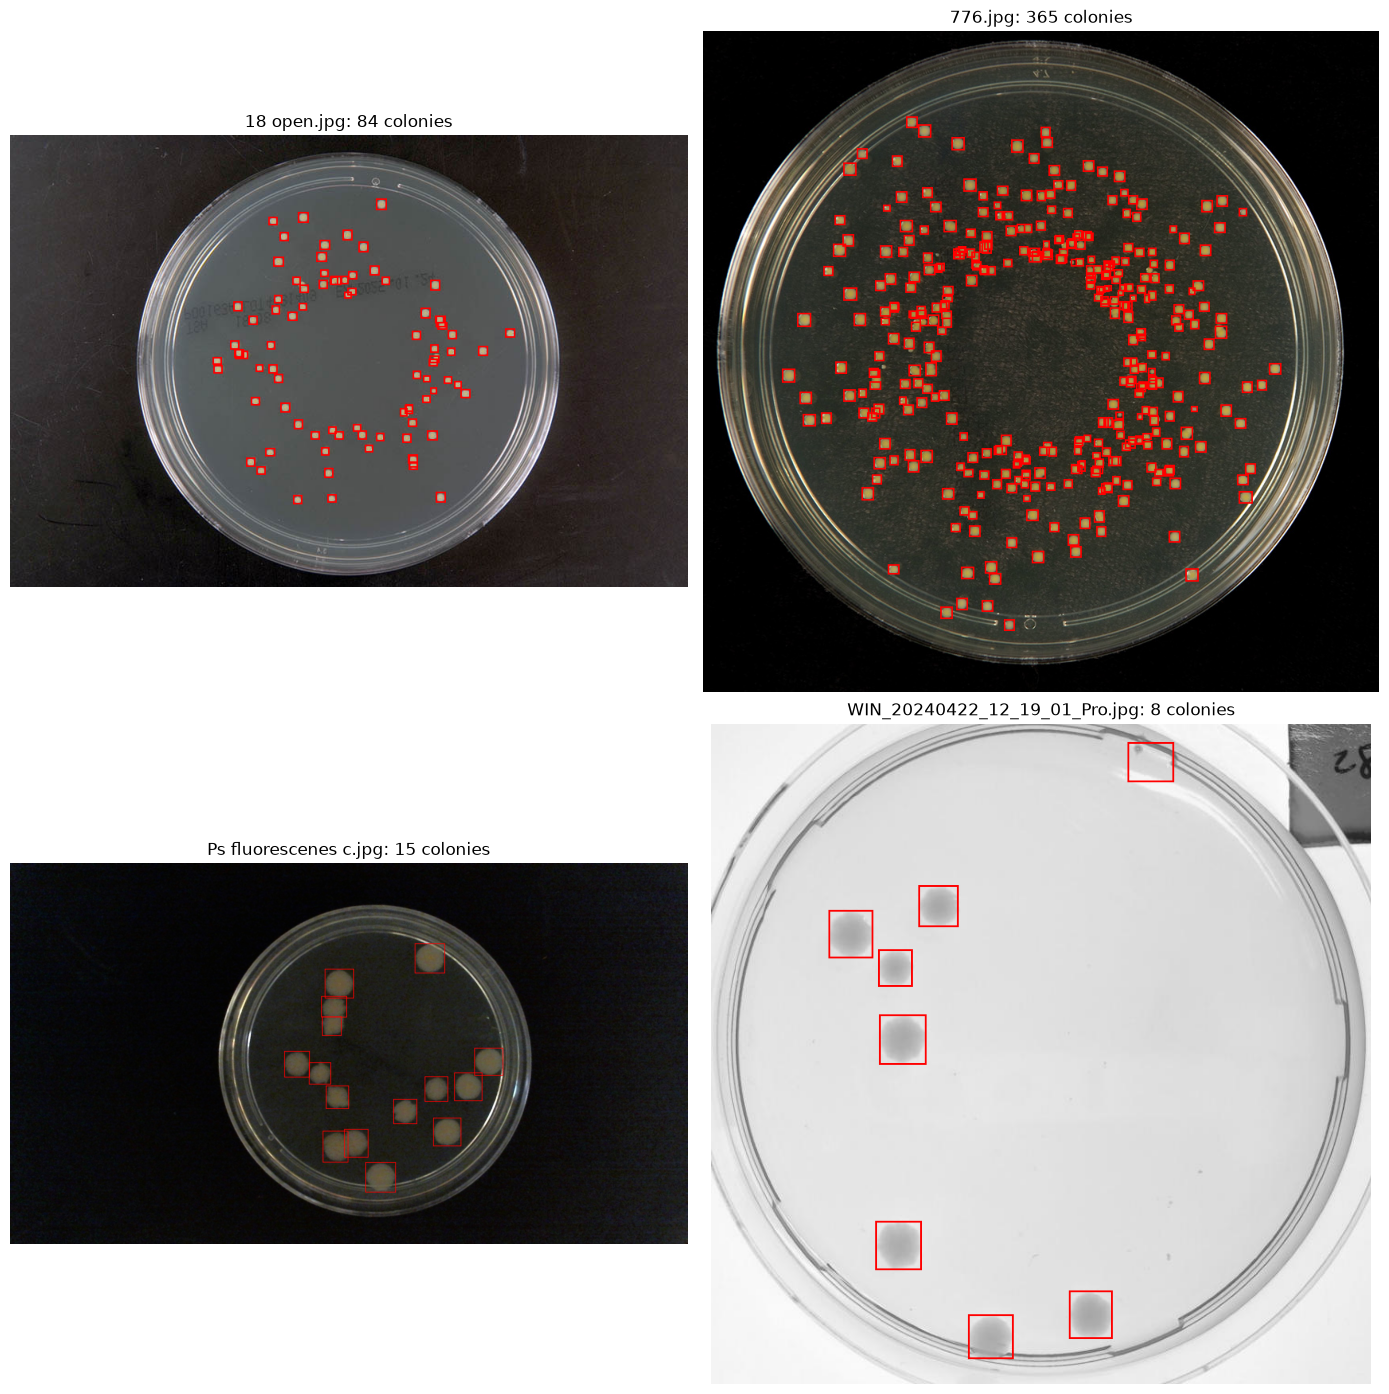

In [35]:
zhenya_val_images = sorted((ZHENYA_ROOT / 'images' / 'val').iterdir())
zhenya_predictions = zhenya_best_model.predict(zhenya_val_images[:4], imgsz=IMAGE_SIZE, device=DEVICE, max_det=1000)

figure, axes = plt.subplots(2, 2, figsize=(14, 14))

for axis, prediction in zip(axes.ravel(), zhenya_predictions):
    image = Image.open(prediction.path).convert('RGB')
    draw = ImageDraw.Draw(image)
    for box in prediction.boxes.xyxy.tolist():
        draw.rectangle(box, outline='red', width=2)

    axis.imshow(image)
    axis.set_title(f'{Path(prediction.path).name}: {len(prediction.boxes)} colonies')
    axis.axis('off')

plt.tight_layout()
plt.show()

## Full

In [17]:
train_table, val_table = train_test_split(detection_table, test_size=0.2, random_state=RANDOM)

print('Train:', len(train_table))
print('Val:', len(val_table))

Train: 47
Val: 12


In [18]:
YOLO_ROOT = Path('data/colonies')

for split, table in [('train', train_table), ('val', val_table)]:
    (YOLO_ROOT / 'images' / split).mkdir(parents=True, exist_ok=True)
    (YOLO_ROOT / 'labels' / split).mkdir(parents=True, exist_ok=True)
    for _, row in table.iterrows():
        image_path = HOMETASK_ROOT / row['person'] / row['image']
        label_path = HOMETASK_ROOT / 'labeled' / f"{row['person']}_part" / 'obj_train_data' / f'{image_path.stem}.txt'
        shutil.copy(image_path, YOLO_ROOT / 'images' / split / image_path.name)
        shutil.copy(label_path, YOLO_ROOT / 'labels' / split / label_path.name)

YOLO_YAML = YOLO_ROOT / 'colonies.yaml'
YOLO_YAML.write_text(
    f'path: {YOLO_ROOT.resolve()}\n'
    'train: images/train\n'
    'val: images/val\n'
    'names:\n'
    '  0: colony\n'
)

123

In [ ]:
model = YOLO('yolo11n.pt')

results = model.train(
    data=YOLO_YAML,
    imgsz=IMAGE_SIZE,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    device=DEVICE,
    seed=RANDOM,
    project='runs',
    name='yolo11n_colonies',
)

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.197 🚀 Python-3.11.15 torch-2.11.0 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/colonies/colonies.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=896, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic

2026/11/22 18:47:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/22 18:47:21 INFO mlflow.store.db.utils: Updating database tables
2026/11/22 18:47:21 INFO mlflow.tracking.fluent: Experiment with name 'runs' does not exist. Creating a new experiment.
2026/11/22 18:47:23 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.


MLflow: logging run_id(daf785d7d6554c0d85c22bf2b35b5f13) to sqlite:////Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/lab7/mlflow.db
MLflow: disable with 'yolo settings mlflow=False'
Using 47 train, 12 val images for fraction=1.0 at imgsz=896
Using 0 dataloader workers
Logging results to /Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/runs/detect/runs/yolo11n_colonies
Starting training for 100 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      1/100      7.39G      1.627      3.103     0.9997        780        896: 100% ━━━━━━━━━━━━ 6/6 3.3s/it 19.8s1.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.5s/it 2.5s
                   all         12       1302      0.549      0.159      0.223      0.132

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/100      9.47G      1.773      1.463     0.9722       1279        896: 100% ━━━━━━━━━━━━ 6/6 1.0s/it 6.

In [31]:
best_model = YOLO(Path(model.trainer.save_dir) / 'weights' / 'best.pt')
val_results = best_model.val(data=YOLO_YAML, imgsz=IMAGE_SIZE, device=DEVICE, split='val')

display(pd.DataFrame({
    'precision': [zhenya_val_results.box.mp, val_results.box.mp],
    'recall': [zhenya_val_results.box.mr, val_results.box.mr],
    'mAP50': [zhenya_val_results.box.map50, val_results.box.map50],
    'mAP50-95': [zhenya_val_results.box.map, val_results.box.map],
}, index=['zhenya', 'full']))


Ultralytics 8.4.197 🚀 Python-3.11.15 torch-2.11.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 975.5±1258.6 MB/s, size: 699.5 KB)
val: Scanning /Users/neprog/Desktop/kse/ml_bio/ml_bio_hw/lab7/data/colonies/labels/val.cache... 12 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 12/12 6.3Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 428 objects (val=428), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=428 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.2it/s 0.8s
                   all         12       1302      0.902      0.782      0.825      0.508
Speed: 0.9ms preprocess, 17.5ms inference, 0.0ms loss, 20.1ms postproc

,precision,recall,mAP50,mAP50-95
zhenya,0.807386,0.699367,0.714530,0.405936
full,0.901653,0.781615,0.825181,0.507501



0: 896x896 355 colonys, 110.2ms
1: 896x896 288 colonys, 110.2ms
2: 896x896 16 colonys, 110.2ms
3: 896x896 485 colonys, 110.2ms
Speed: 3.9ms preprocess, 110.2ms inference, 9.9ms postprocess per image at shape (1, 3, 896, 896)


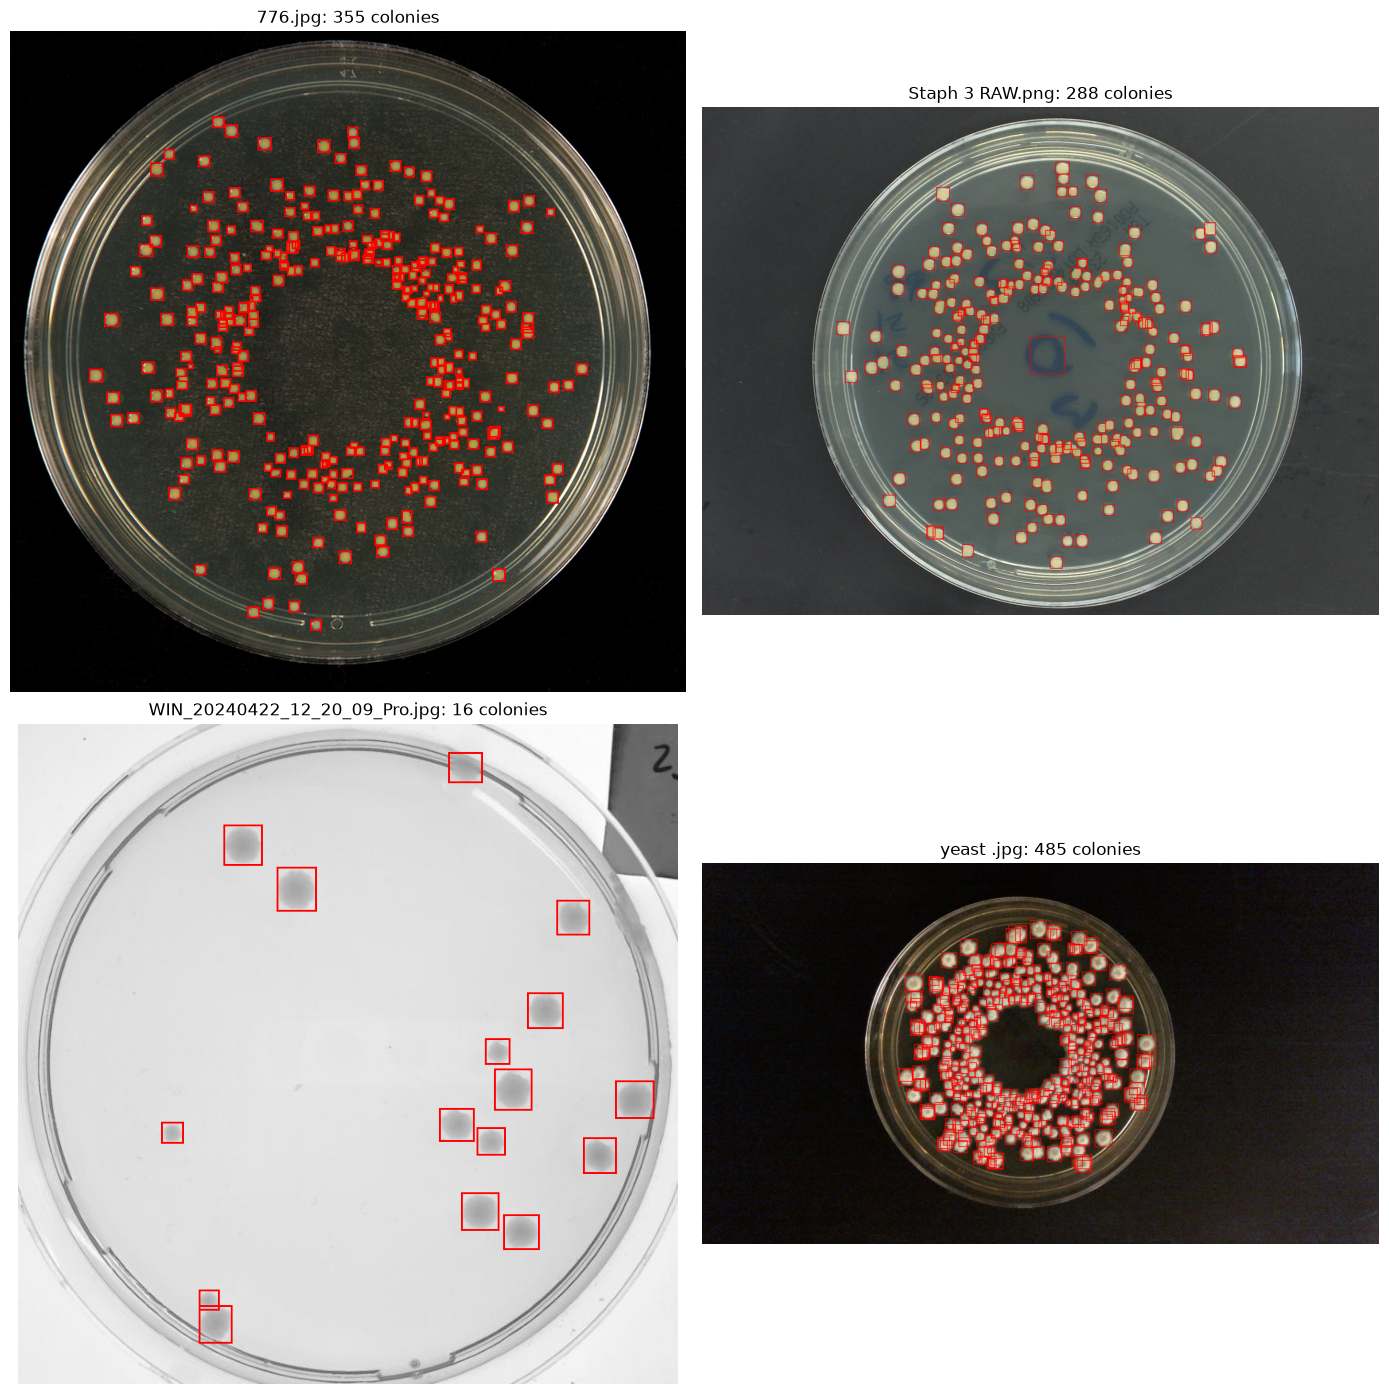

In [36]:
val_images = sorted((YOLO_ROOT / 'images' / 'val').iterdir())
predictions = best_model.predict([val_images[i] for i in [1, 4, 8, 11]], imgsz=IMAGE_SIZE, device=DEVICE, max_det=1000)

figure, axes = plt.subplots(2, 2, figsize=(14, 14))

for axis, prediction in zip(axes.ravel(), predictions):
    image = Image.open(prediction.path).convert('RGB')
    draw = ImageDraw.Draw(image)
    for box in prediction.boxes.xyxy.tolist():
        draw.rectangle(box, outline='red', width=2)

    axis.imshow(image)
    axis.set_title(f'{Path(prediction.path).name}: {len(prediction.boxes)} colonies')
    axis.axis('off')

plt.tight_layout()
plt.show()

increase in number of train data improved the model, who would've guessed

3. What are the most common YOLO errors: missed objects, false detections, or inaccurate box boundaries?
missed objects is the most common one, espesially in the crowded areas, the second most popular is box boundaries - also in the crowded places. And one misidentified letter from the dish was identified as colony
4. Does the uncertainty ranking select images that look difficult or ambiguous to a human annotator?
mostly yes, and that's expected as humans(we) labeled it, where we were uncertain translated onto the model 